In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit

In [2]:
%matplotlib inline

L = 30
N = L * L
J = 1.0
kB = 1.0
T_values = np.arange(1, 4 + 0.05, 0.05)   # da 1 a 4 con passo 0.05
nmcs = 900_000                             # 1 passo MC = 1 tentativo di flip

In [3]:
def init_lattice():
    return np.random.choice([-1, 1], size=(L, L))

@njit
def energy(s):
    E = 0.0
    for i in range(L):
        for j in range(L):
            E -= J * s[i, j] * (s[i, (j + 1) % L] + s[(i + 1) % L, j])
    return E

@njit
def magnetization(s):
    return np.sum(s)

In [4]:
@njit
def metropolis_step(s, T):
    i = np.random.randint(0, L)
    j = np.random.randint(0, L)
    vicini = (s[(i + 1) % L, j] + s[(i - 1) % L, j] +
              s[i, (j + 1) % L] + s[i, (j - 1) % L])
    dE = 2.0 * J * s[i, j] * vicini
    if dE <= 0 or np.random.random() < np.exp(-dE / (kB * T)):
        dM = -2.0 * s[i, j]      # lo spin passa da s a -s
        s[i, j] = -s[i, j]
        return dE, dM
    return 0.0, 0.0

In [5]:
s = init_lattice()
print("E/N iniziale:", energy(s) / N)
print("M/N iniziale:", magnetization(s) / N)
for _ in range(1000):
    metropolis_step(s, 2.0)
print("E/N dopo 1000 passi:", energy(s) / N)

E/N iniziale: -0.03111111111111111
M/N iniziale: -0.06
E/N dopo 1000 passi: -0.72


In [6]:
nequil = 200_000    # passi scartati per l'equilibrio

@njit
def run(s, T, nmcs, nequil):
    E = energy(s)
    M = float(magnetization(s))
    n = nmcs - nequil
    sE = sE2 = sM = sAbsM = sM2 = 0.0
    for t in range(nmcs):
        dE, dM = metropolis_step(s, T)
        E += dE
        M += dM
        if t >= nequil:
            sE += E
            sE2 += E * E
            sM += M
            sAbsM += abs(M)
            sM2 += M * M
    return sE / n, sE2 / n, sM / n, sAbsM / n, sM2 / n

In [7]:
nT = len(T_values)
E_avg = np.zeros(nT); E2_avg = np.zeros(nT)
M_avg = np.zeros(nT); absM_avg = np.zeros(nT); M2_avg = np.zeros(nT)

for k, T in enumerate(T_values):
    s = init_lattice()
    E_avg[k], E2_avg[k], M_avg[k], absM_avg[k], M2_avg[k] = run(s, T, nmcs, nequil)

n = nmcs - nequil

# errore "naive" senza binning: sigma / sqrt(n)
errE = np.sqrt((E2_avg - E_avg**2) / n) / N
errM = np.sqrt((M2_avg - M_avg**2) / n) / N

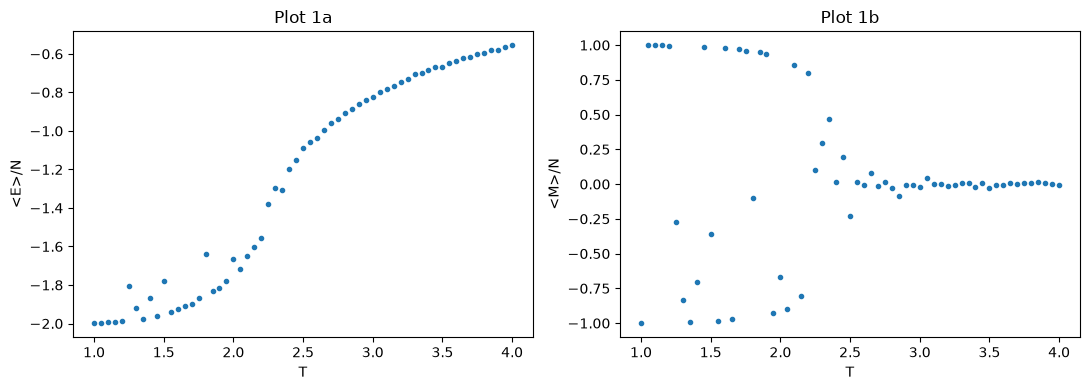

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].errorbar(T_values, E_avg / N, yerr=errE, fmt='o', ms=3)
ax[0].set_xlabel("T"); ax[0].set_ylabel("<E>/N"); ax[0].set_title("Plot 1a")

ax[1].errorbar(T_values, M_avg / N, yerr=errM, fmt='o', ms=3)
ax[1].set_xlabel("T"); ax[1].set_ylabel("<M>/N"); ax[1].set_title("Plot 1b")

plt.tight_layout()
plt.show()

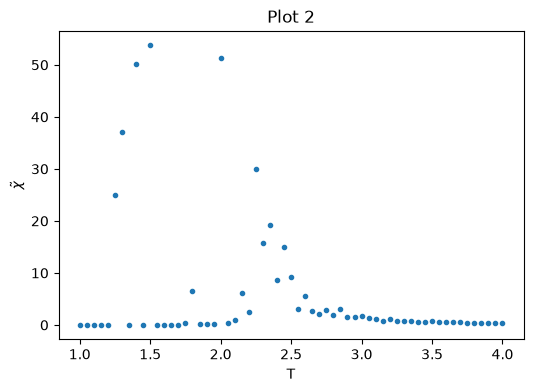

In [9]:
chi = (M2_avg - absM_avg**2) / (kB * T_values * N)

plt.figure(figsize=(6, 4))
plt.plot(T_values, chi, 'o', ms=3)
plt.xlabel("T"); plt.ylabel(r"$\tilde{\chi}$"); plt.title("Plot 2")
plt.show()

In [10]:
# da fluttuazioni
c_fluct = (E2_avg - E_avg**2) / (kB * T_values**2 * N)

# dalla derivata di <E>/N rispetto a T (differenze finite)
c_deriv = np.gradient(E_avg / N, T_values)

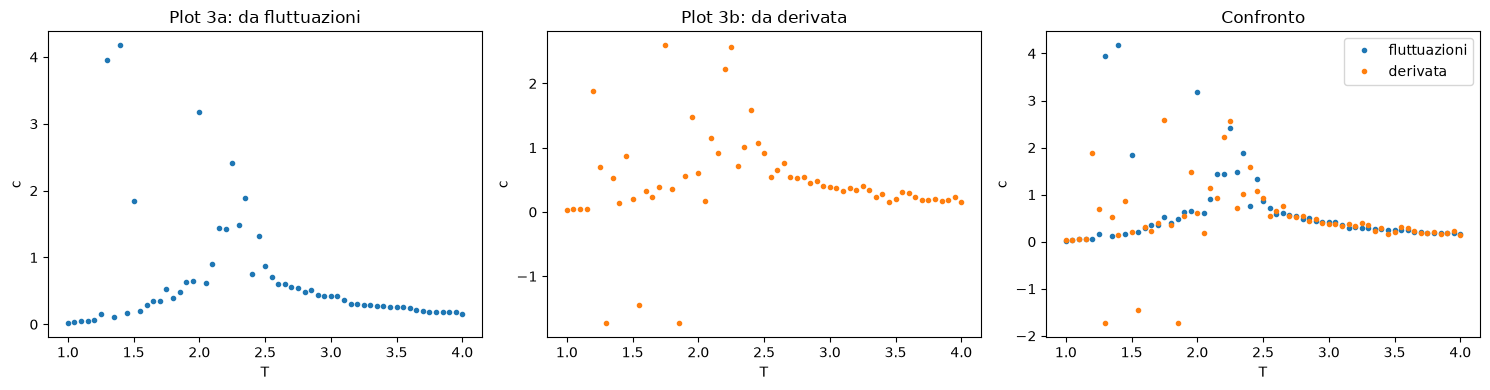

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].plot(T_values, c_fluct, 'o', ms=3)
ax[0].set_title("Plot 3a: da fluttuazioni")

ax[1].plot(T_values, c_deriv, 'o', ms=3, color='C1')
ax[1].set_title("Plot 3b: da derivata")

ax[2].plot(T_values, c_fluct, 'o', ms=3, label="fluttuazioni")
ax[2].plot(T_values, c_deriv, 'o', ms=3, label="derivata")
ax[2].set_title("Confronto"); ax[2].legend()

for a in ax:
    a.set_xlabel("T"); a.set_ylabel("c")

plt.tight_layout()
plt.show()

In [12]:
nsweeps = 1000
nequil_sw = 200      # sweep scartati per l'equilibrio (= 200.000 flip, come prima)

@njit
def run_sweep(s, T, nsweeps, nequil_sw):
    E = energy(s)
    M = float(magnetization(s))
    n = nsweeps - nequil_sw
    sE = sE2 = sM = sAbsM = sM2 = 0.0
    for t in range(nsweeps):
        for k in range(N):                 # uno sweep = N tentativi di flip
            dE, dM = metropolis_step(s, T)
            E += dE
            M += dM
        if t >= nequil_sw:                 # misura UNA volta per sweep
            sE += E
            sE2 += E * E
            sM += M
            sAbsM += abs(M)
            sM2 += M * M
    return sE / n, sE2 / n, sM / n, sAbsM / n, sM2 / n

In [13]:
E4 = np.zeros(nT); E24 = np.zeros(nT); M4 = np.zeros(nT)
absM4 = np.zeros(nT); M24 = np.zeros(nT)

for k, T in enumerate(T_values):
    s = init_lattice()
    E4[k], E24[k], M4[k], absM4[k], M24[k] = run_sweep(s, T, nsweeps, nequil_sw)

n4 = nsweeps - nequil_sw
errE4 = np.sqrt((E24 - E4**2) / n4) / N
errM4 = np.sqrt((M24 - M4**2) / n4) / N

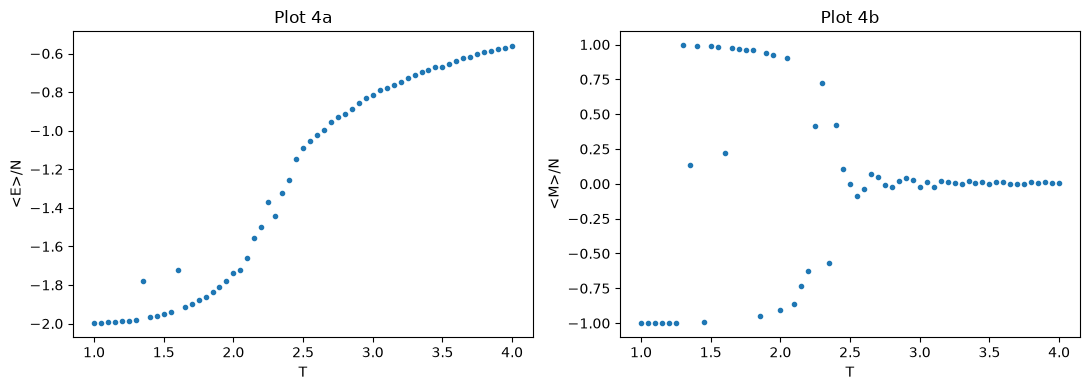

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].errorbar(T_values, E4 / N, yerr=errE4, fmt='o', ms=3)
ax[0].set_xlabel("T"); ax[0].set_ylabel("<E>/N"); ax[0].set_title("Plot 4a")

ax[1].errorbar(T_values, M4 / N, yerr=errM4, fmt='o', ms=3)
ax[1].set_xlabel("T"); ax[1].set_ylabel("<M>/N"); ax[1].set_title("Plot 4b")

plt.tight_layout()
plt.show()

In [15]:
T0 = 2.0

@njit
def serie_flip(s, T, nmcs, nequil):
    E = energy(s); M = float(magnetization(s))
    Es = np.zeros(nmcs - nequil); Ms = np.zeros(nmcs - nequil)
    for t in range(nmcs):
        dE, dM = metropolis_step(s, T)
        E += dE; M += dM
        if t >= nequil:
            Es[t - nequil] = E
            Ms[t - nequil] = abs(M)
    return Es, Ms

@njit
def serie_sweep(s, T, nsweeps, nequil_sw):
    E = energy(s); M = float(magnetization(s))
    Es = np.zeros(nsweeps - nequil_sw); Ms = np.zeros(nsweeps - nequil_sw)
    for t in range(nsweeps):
        for k in range(N):
            dE, dM = metropolis_step(s, T)
            E += dE; M += dM
        if t >= nequil_sw:
            Es[t - nequil_sw] = E
            Ms[t - nequil_sw] = abs(M)
    return Es, Ms

E_flip, M_flip = serie_flip(init_lattice(), T0, nmcs, nequil)
E_sw, M_sw = serie_sweep(init_lattice(), T0, nsweeps, nequil_sw)

In [16]:
def autocorr(x, tmax):
    """C(t) = (<x(0)x(t)> - <x>^2) / (<x^2> - <x>^2), per t = 0..tmax-1"""
    x = x - x.mean()
    n = len(x)
    f = np.fft.rfft(x, 2 * n)                 # zero-padding per evitare effetti periodici
    acf = np.fft.irfft(f * np.conj(f))[:tmax]
    acf = acf / np.arange(n, n - tmax, -1)    # media sulle coppie disponibili
    return acf / acf[0]

C_E_flip = autocorr(E_flip, 20000)
C_M_flip = autocorr(M_flip, 20000)
C_E_sw = autocorr(E_sw, 100)
C_M_sw = autocorr(M_sw, 100)

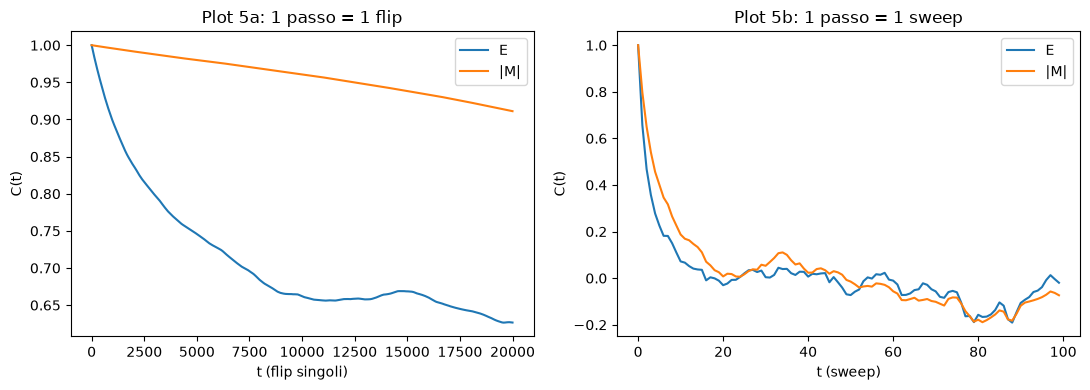

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(C_E_flip, label="E")
ax[0].plot(C_M_flip, label="|M|")
ax[0].set_xlabel("t (flip singoli)"); ax[0].set_ylabel("C(t)")
ax[0].set_title("Plot 5a: 1 passo = 1 flip"); ax[0].legend()

ax[1].plot(C_E_sw, label="E")
ax[1].plot(C_M_sw, label="|M|")
ax[1].set_xlabel("t (sweep)"); ax[1].set_ylabel("C(t)")
ax[1].set_title("Plot 5b: 1 passo = 1 sweep"); ax[1].legend()

plt.tight_layout()
plt.show()